In [1]:
from pathlib import Path
import tensorflow as tf

BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATOS = BASE / "data" / "processed"

CLASES = [
    "with_mask",
    "without_mask",
    "mask_weared_incorrect",
]

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATOS / "entrenamiento",
    class_names=CLASES,
    image_size=(128, 128),
    batch_size=32,
    label_mode="int",
    shuffle=True,
    seed=42,
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATOS / "validacion",
    class_names=CLASES,
    image_size=(128, 128),
    batch_size=32,
    label_mode="int",
    shuffle=False,
)

print("Orden de etiquetas:")
for numero, clase in enumerate(CLASES):
    print(numero, "=", clase)

for imagenes, etiquetas in train_ds.take(1):
    print("Forma del lote de imágenes:", imagenes.shape)
    print("Forma del lote de etiquetas:", etiquetas.shape)
    print("Valores de píxel:", imagenes.numpy().min(), "a", imagenes.numpy().max())

Found 2574 files belonging to 3 classes.
Found 545 files belonging to 3 classes.
Orden de etiquetas:
0 = with_mask
1 = without_mask
2 = mask_weared_incorrect
Forma del lote de imágenes: (32, 128, 128, 3)
Forma del lote de etiquetas: (32,)
Valores de píxel: 0.0 a 255.0


In [2]:
tf.keras.utils.set_random_seed(42)

modelo_basico = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)),
    tf.keras.layers.Rescaling(1.0 / 255),

    tf.keras.layers.Conv2D(16, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(3, activation="softmax"),
])

modelo_basico.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

modelo_basico.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 28800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │       921,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 926,819 (3.54 MB)

 Trainable params: 926,819 (3.54 MB)

 Non-trainable params: 0 (0.00 B)

In [3]:
historial_basico = modelo_basico.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
)

Epoch 1/10


/Users/eduardoabundiz/Desktop/face_mask_detection/.venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.8625 - loss: 0.3680 - val_accuracy: 0.9119 - val_loss: 0.2170
Epoch 2/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.9312 - loss: 0.2255 - val_accuracy: 0.9468 - val_loss: 0.1644
Epoch 3/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.9367 - loss: 0.1822 - val_accuracy: 0.9376 - val_loss: 0.1732
Epoch 4/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.9444 - loss: 0.1716 - val_accuracy: 0.9523 - val_loss: 0.1643
Epoch 5/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.9441 - loss: 0.1694 - val_accuracy: 0.9523 - val_loss: 0.1470
Epoch 6/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.9526 - loss: 0.1363 - val_accuracy: 0.9578 - val_loss: 0.1345
Epoch 7/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.9600 - loss: 0.1151 - val_accuracy: 0.9523 - val_loss: 0.1409
Epoch 8/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.9573 - loss: 0.1173 - val_accuracy: 0.9431 - val_loss: 0.

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Resultados en validación:
                       precision    recall  f1-score   support

            with_mask     0.9864    0.9581    0.9721       454
         without_mask     0.8409    0.9867    0.9080        75
mask_weared_incorrect     0.4375    0.4375    0.4375        16

             accuracy                         0.9468       545
            macro avg     0.7549    0.7941    0.7725       545
         weighted avg     0.9503    0.9468    0.9476       545

Matriz de confusión:
[[435  10   9]
 [  1  74   0]
 [  5   4   7]]


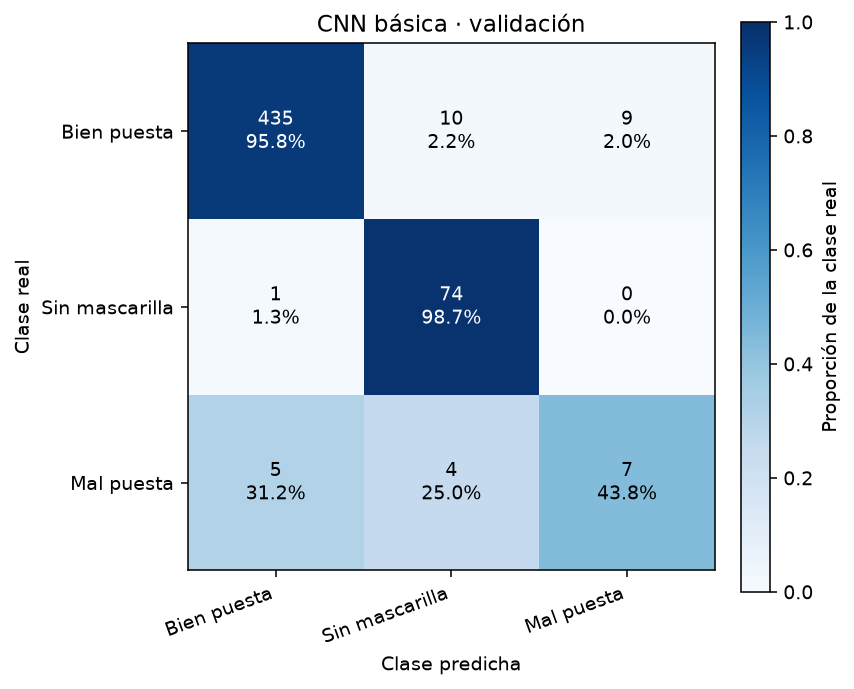

In [4]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

etiquetas_reales = np.concatenate([
    etiquetas.numpy()
    for _, etiquetas in val_ds
])

probabilidades = modelo_basico.predict(val_ds)
etiquetas_predichas = np.argmax(probabilidades, axis=1)

print("Resultados en validación:")
print(
    classification_report(
        etiquetas_reales,
        etiquetas_predichas,
        labels=[0, 1, 2],
        target_names=CLASES,
        digits=4,
        zero_division=0,
    )
)

print("Matriz de confusión:")
print(
    confusion_matrix(
        etiquetas_reales,
        etiquetas_predichas,
        labels=[0, 1, 2],
    )
)
import matplotlib.pyplot as plt


def graficar_matriz(etiquetas_reales, etiquetas_predichas, titulo):
    matriz = confusion_matrix(
        etiquetas_reales, etiquetas_predichas, labels=[0, 1, 2]
    )
    porcentajes = matriz / matriz.sum(axis=1, keepdims=True)
    nombres = ["Bien puesta", "Sin mascarilla", "Mal puesta"]

    fig, eje = plt.subplots(figsize=(6, 5), layout="constrained")
    imagen = eje.imshow(porcentajes, cmap="Blues", vmin=0, vmax=1)

    for fila in range(3):
        for columna in range(3):
            valor = porcentajes[fila, columna]
            eje.text(
                columna, fila,
                f"{matriz[fila, columna]}\n{valor:.1%}",
                ha="center", va="center",
                color="white" if valor > 0.5 else "black",
            )

    eje.set_xticks(range(3), nombres, rotation=20, ha="right")
    eje.set_yticks(range(3), nombres)
    eje.set_xlabel("Clase predicha")
    eje.set_ylabel("Clase real")
    eje.set_title(titulo)
    fig.colorbar(imagen, ax=eje, label="Proporción de la clase real")
    plt.show()

graficar_matriz(etiquetas_reales, etiquetas_predichas, "CNN básica · validación")


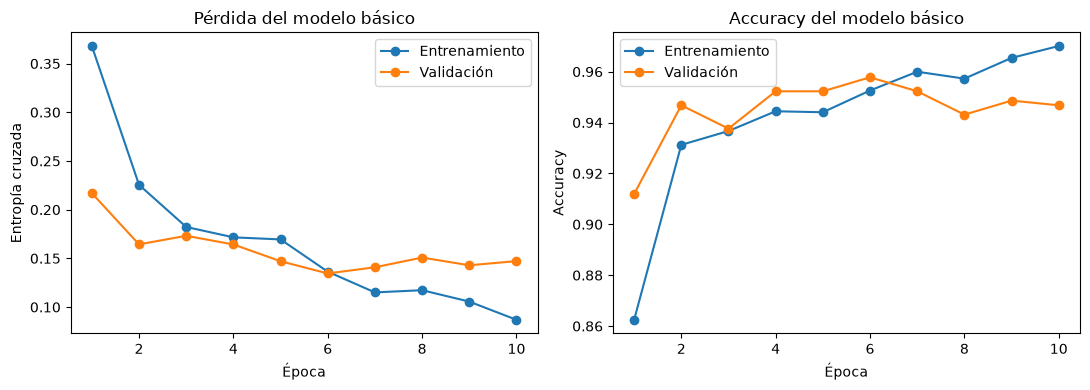

In [5]:
import matplotlib.pyplot as plt

epocas = range(1, len(historial_basico.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(
    epocas, historial_basico.history["loss"],
    marker="o", label="Entrenamiento"
)
axes[0].plot(
    epocas, historial_basico.history["val_loss"],
    marker="o", label="Validación"
)
axes[0].set_title("Pérdida del modelo básico")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Entropía cruzada")
axes[0].legend()

axes[1].plot(
    epocas, historial_basico.history["accuracy"],
    marker="o", label="Entrenamiento"
)
axes[1].plot(
    epocas, historial_basico.history["val_accuracy"],
    marker="o", label="Validación"
)
axes[1].set_title("Accuracy del modelo básico")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

In [6]:
tf.keras.utils.set_random_seed(42)

modelo_profundo = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)),
    tf.keras.layers.Rescaling(1.0 / 255),

    tf.keras.layers.Conv2D(16, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(3, activation="softmax"),
])

modelo_profundo.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

modelo_profundo.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │       401,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 425,123 (1.62 MB)

 Trainable params: 425,123 (1.62 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
historial_profundo = modelo_profundo.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
)

Epoch 1/10


/Users/eduardoabundiz/Desktop/face_mask_detection/.venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.8765 - loss: 0.3868 - val_accuracy: 0.9321 - val_loss: 0.2191
Epoch 2/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.9343 - loss: 0.2129 - val_accuracy: 0.9486 - val_loss: 0.1593
Epoch 3/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.9390 - loss: 0.1765 - val_accuracy: 0.9523 - val_loss: 0.1565
Epoch 4/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - accuracy: 0.9425 - loss: 0.1707 - val_accuracy: 0.9413 - val_loss: 0.1729
Epoch 5/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.9476 - loss: 0.1432 - val_accuracy: 0.9505 - val_loss: 0.1809
Epoch 6/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - accuracy: 0.9534 - loss: 0.1318 - val_accuracy: 0.9413 - val_loss: 0.1984
Epoch 7/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - accuracy: 0.9514 - loss: 0.1226 - val_accuracy: 0.9376 - val_loss: 0.1571
Epoch 8/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.9639 - loss: 0.1045 - val_accuracy: 0.9468 - val_loss: 0.

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
Modelo profundo: resultados en validación
                       precision    recall  f1-score   support

            with_mask     0.9780    0.9780    0.9780       454
         without_mask     0.8471    0.9600    0.9000        75
mask_weared_incorrect     0.6667    0.2500    0.3636        16

             accuracy                         0.9541       545
            macro avg     0.8306    0.7293    0.7472       545
         weighted avg     0.9508    0.9541    0.9492       545

Matriz de confusión:
[[444   8   2]
 [  3  72   0]
 [  7   5   4]]


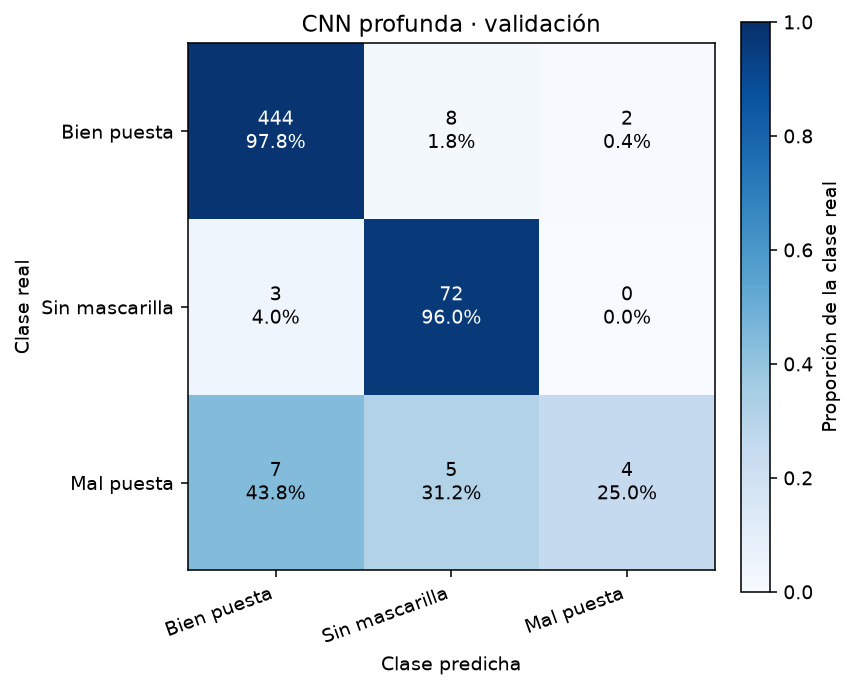

In [8]:
probabilidades_profundo = modelo_profundo.predict(val_ds)
predicciones_profundo = np.argmax(
    probabilidades_profundo, axis=1
)

print("Modelo profundo: resultados en validación")
print(
    classification_report(
        etiquetas_reales,
        predicciones_profundo,
        labels=[0, 1, 2],
        target_names=CLASES,
        digits=4,
        zero_division=0,
    )
)

print("Matriz de confusión:")
print(
    confusion_matrix(
        etiquetas_reales,
        predicciones_profundo,
        labels=[0, 1, 2],
    )
)
graficar_matriz(
    etiquetas_reales, predicciones_profundo,
    "CNN profunda · validación",
)


In [9]:
carpeta_modelos = BASE / "models"
carpeta_modelos.mkdir(parents=True, exist_ok=True)

modelo_basico.save(carpeta_modelos / "cnn_basica.keras")
modelo_profundo.save(carpeta_modelos / "cnn_profunda.keras")

print("Básico:", (carpeta_modelos / "cnn_basica.keras").exists())
print("Profundo:", (carpeta_modelos / "cnn_profunda.keras").exists())

Básico: True
Profundo: True


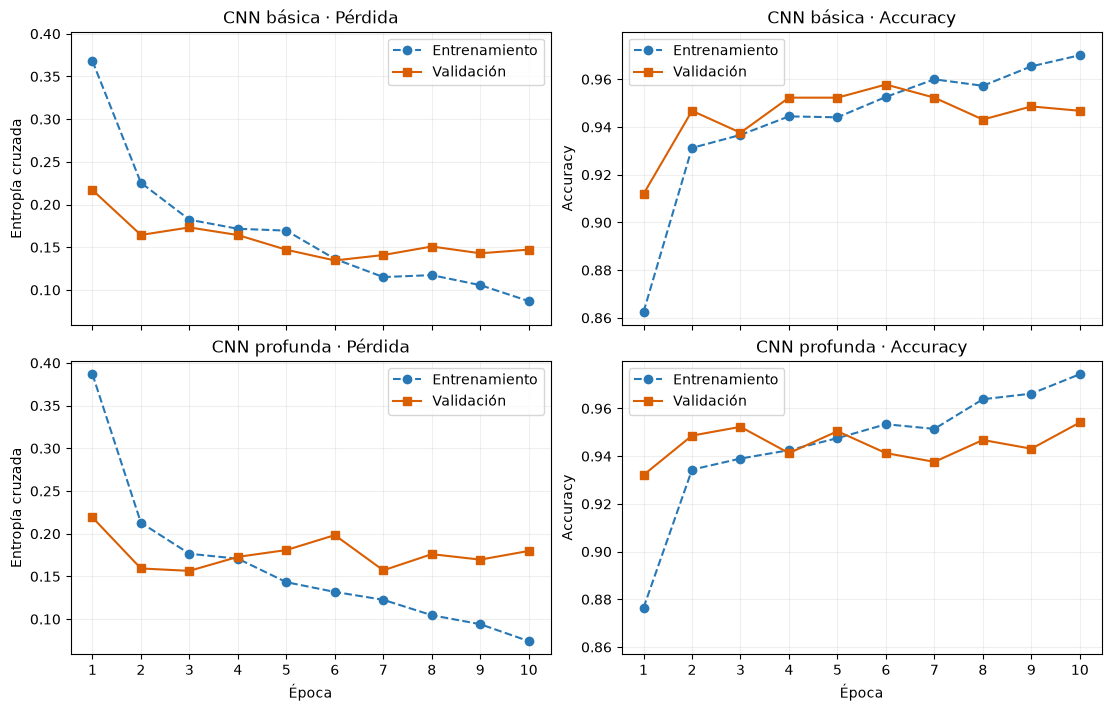

In [16]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(11, 7),
    sharex=True,
    sharey="col",
    layout="constrained",
)

modelos = [
    ("CNN básica", historial_basico),
    ("CNN profunda", historial_profundo),
]

metricas = [
    ("loss", "val_loss", "Pérdida", "Entropía cruzada"),
    ("accuracy", "val_accuracy", "Accuracy", "Accuracy"),
]

for fila, (nombre_modelo, historial) in enumerate(modelos):
    epocas = range(1, len(historial.history["loss"]) + 1)

    for columna, (
        metrica_train,
        metrica_val,
        titulo,
        etiqueta_y,
    ) in enumerate(metricas):
        eje = axes[fila, columna]

        eje.plot(
            epocas,
            historial.history[metrica_train],
            color="#2878B5",
            marker="o",
            linestyle="--",
            label="Entrenamiento",
        )

        eje.plot(
            epocas,
            historial.history[metrica_val],
            color="#D95F02",
            marker="s",
            linestyle="-",
            label="Validación",
        )

        eje.set_title(f"{nombre_modelo} · {titulo}")
        eje.set_ylabel(etiqueta_y)
        eje.set_xticks(range(1, 11))
        eje.grid(alpha=0.2)
        eje.legend(loc="best")

for eje in axes[1]:
    eje.set_xlabel("Época")

ruta_curvas = (
    BASE / "outputs" / "figuras" / "curvas_comparativas.png"
)
fig.savefig(ruta_curvas, dpi=180, bbox_inches="tight")

plt.show()

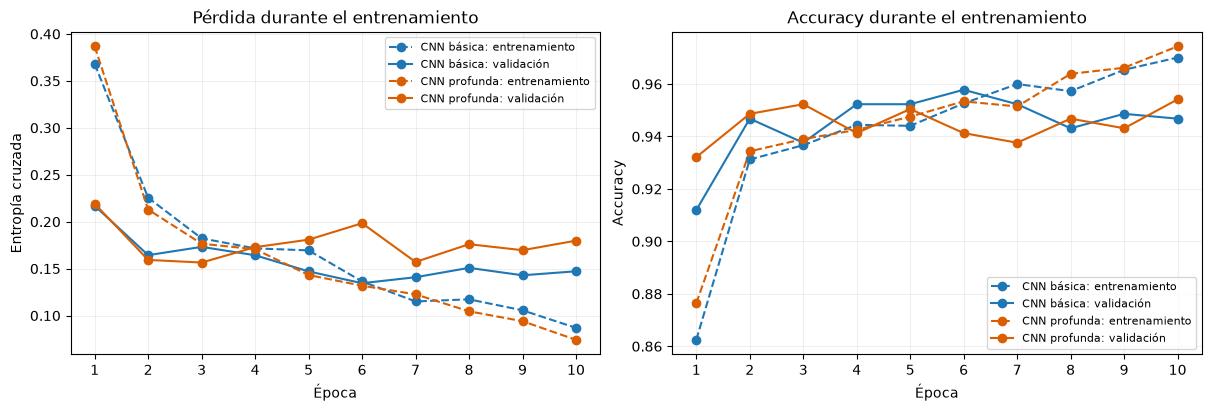

In [15]:
fig, axes = plt.subplots(
    1, 2, figsize=(12, 4), layout="constrained"
)

modelos = [
    ("CNN básica", historial_basico, "#1f77b4"),
    ("CNN profunda", historial_profundo, "#d95f02"),
]

for nombre, historial, color in modelos:
    epocas = range(1, len(historial.history["loss"]) + 1)

    axes[0].plot(
        epocas, historial.history["loss"],
        "--", color=color, marker="o",
        label=f"{nombre}: entrenamiento",
    )
    axes[0].plot(
        epocas, historial.history["val_loss"],
        "-", color=color, marker="o",
        label=f"{nombre}: validación",
    )

    axes[1].plot(
        epocas, historial.history["accuracy"],
        "--", color=color, marker="o",
        label=f"{nombre}: entrenamiento",
    )
    axes[1].plot(
        epocas, historial.history["val_accuracy"],
        "-", color=color, marker="o",
        label=f"{nombre}: validación",
    )

axes[0].set_title("Pérdida durante el entrenamiento")
axes[0].set_ylabel("Entropía cruzada")

axes[1].set_title("Accuracy durante el entrenamiento")
axes[1].set_ylabel("Accuracy")

for eje in axes:
    eje.set_xlabel("Época")
    eje.set_xticks(range(1, 11))
    eje.grid(alpha=0.2)
    eje.legend(fontsize=8)

ruta_curvas = (
    BASE / "outputs" / "figuras" / "curvas_superpuestas.png"
)
ruta_curvas.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(ruta_curvas, dpi=180, bbox_inches="tight")

plt.show()